# Helper code for the report
Each cell reproduces a number, table or figure in the final report. Run from the project folder after the experiment notebooks, so results_10_epochs/ and runs_10_epochs/ exist.

# Imports

In [8]:
import random
from cory_data_wrapper import grabcut_mask_from_bbox, build_mask_from_bbox, composite_background, IN9BoundingBoxDataset, load_bbox_csv, composite_background
import cv2
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from scipy import stats
from pathlib import Path
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import pathlib
import numpy as np
from torchvision import transforms
from PIL import Image
from cory_data_wrapper import ImageFolderEval, fix_test_labels, IMAGENET_MEAN, IMAGENET_STD, VIT_MEAN, VIT_STD
import json
import time
import pandas as pd
import torch
from cory_utils import CNNModel, ViTModel
import datetime

## 1. GrabCut and donor success rates (Section III-B)
How often GrabCut finds the object (the rest use the bounding box, 16.0%) and how often a donor background is found. Checks the full training set


In [2]:
# Script generated by Generative AI and edited by me, only for report purposes and code is fully understood
# Note code takes roughly 1.5h to check the full dataset, if you want a rough estimation, set n_images to at least 500 values to get a good approximation of the distribution of image masks found by GrabCut (~500 takes about a minute)

# Same paths and image size as the notebooks
TRAIN = pathlib.Path("data") / "rebuild" / "in9_train"
BBOXS = pathlib.Path("data") / "LOC_train_solution.csv"
IMG_SIZE = 224

def check_augmentation(dataset, n_images=500, seed=0):
    """Counts how often GrabCut works and how often a donor background is found."""
    # fixed seed, so the sample is repeatable
    rng = random.Random(seed)
    # n_images random training images
    sample = rng.sample(range(len(dataset)), n_images)

    # images where GrabCut found the object
    grabcut_ok = 0
    # images that would get a new background
    swapped = 0

    for i in sample:
        # base dataset gives (image, label, box)
        image, label, bbox = dataset[i]
        height, width = image.shape[1], image.shape[2]

        # Does GrabCut work on this image, second return value is True then
        _, ok = grabcut_mask_from_bbox(image, bbox)
        if ok:
            grabcut_ok += 1

        # Try up to 5 random other images, as the real augmentation does.
        for _ in range(5):
            j = rng.randrange(len(dataset))
            # make sure an image is never its own donor
            if j == i:
                continue
            _, _, donor_bbox = dataset[j]
            # 1 = background, 0 = inside the box
            donor_mask = build_mask_from_bbox(donor_bbox, (height, width))
            # donor box leaves at least 30% background
            if donor_mask.mean().item() >= 0.3:
                swapped += 1
                break

    print(f"Checked {n_images} of {len(dataset)} training images")
    print(f"GrabCut worked:        {grabcut_ok / n_images:.1%}")
    print(f"GrabCut used the box:  {1 - grabcut_ok / n_images:.1%}")
    print(f"Donor found (swapped): {swapped / n_images:.1%}")
    print(f"Kept own background:   {1 - swapped / n_images:.1%}")

boxes = load_bbox_csv(BBOXS)
train_images = IN9BoundingBoxDataset(TRAIN, boxes, image_size=IMG_SIZE)
check_augmentation(train_images, n_images=len(train_images), seed=0)

Checked 72036 of 72036 training images
GrabCut worked:        84.0%
GrabCut used the box:  16.0%
Donor found (swapped): 100.0%
Kept own background:   0.0%


## 2. Augmentation example strip (Fig. 1)
Original image, GrabCut mask, donor with its object box blacked out, and the composited result. Needs train_images from cell 1.

In [ ]:
"""
Creates a strip of images showing an original training image and the augmentation process
"""
# change train_images[0] to look at another training image
image, label, bbox = train_images[0]
# 1 = background, 0 = object
mask, used_grabcut = grabcut_mask_from_bbox(image, bbox)
donor, _, donor_bbox = train_images[random.randrange(len(train_images))]
# black out the donor's object box
donor = donor * build_mask_from_bbox(donor_bbox, image.shape[1:])
# fg * (1 - m) + m * bg apply the composition
combined = composite_background(image, mask, donor)

# show the original, mask, blacked-out donor and composited image side by side
row = np.hstack([t.permute(1, 2, 0).numpy() for t in (image, mask.expand(3, -1, -1), donor, combined)])
plt.figure(figsize=(12, 5))
plt.imshow(row)
plt.axis("off")
Path("figures_10_epochs").mkdir(exist_ok=True)
plt.savefig("figures_10_epochs/augmentation_example.png")
plt.show()

## 3. Total training time
GPU hours for the final runs (from the results files) and the learning rate search (from the TensorBoard logs).

In [12]:
# Training time of the final runs, from the three results files used in the report
files = ["cnn_results.json", "vit_results.json", "vit_small_results.json"]
final = sum(r["training_time_in_secs"] for f in files for r in json.load(open(f"results_10_epochs/{f}"))) / 3600

# learning rate search: time from the first to the last event of each trial folder
trials = {}
for f in Path("runs_10_epochs").rglob("events.out.tfevents.*"):
    if any(p.startswith("hpsearch") for p in f.parts):
        times = [e.wall_time for e in EventFileLoader(str(f)).Load()]
        lo, hi = trials.get(f.parent.parent, (float("inf"), 0))
        trials[f.parent.parent] = (min(lo, min(times)), max(hi, max(times)))
search = sum(hi - lo for lo, hi in trials.values()) / 3600

print(f"final runs: {final:.1f} h, learning rate search: {search:.1f} h, total: {final + search:.1f} h")

final runs: 32.0 h, learning rate search: 4.9 h, total: 36.9 h


## 4. Statistical tests with Holm correction
Mean ± SD, change, effect size and seeds reduced for each metric, the 4 Wilcoxon and 4 Mann-Whitney U tests with Holm correction over 8 tests.

In [4]:
# Settings
RESULTS_DIR = "results_10_epochs"
MODEL_FILES = {"ResNet-50": "cnn", "ViT-B/16": "vit", "ViT-S/16": "vit_small"}
METRICS = ["bg_gap", "no_fg_accuracy", "original_accuracy"]
# Only the reliance metrics are tested, ViT-S/16 and original accuracy are descriptive
TESTED_METRICS = ["bg_gap", "no_fg_accuracy"]

# Reduction in each metric for each model, in percentage points, one value per seed
reductions = {}
# Scores of the models trained on the original images, one value per seed, for the baseline comparison
baseline_scores = {}
test_names = []
raw_p_values = []

for model_name, file_prefix in MODEL_FILES.items():
    # Load the runs for this model and split them by training condition
    with open(f"{RESULTS_DIR}/{file_prefix}_results.json") as file:
        all_runs = json.load(file)
    metrics_by_seed = {"original": {}, "augmented": {}}
    # Group each run's metrics by training condition and seed
    for run in all_runs:
        metrics_by_seed[run["data_type"]][run["seed"]] = run["reliance_metrics"]
    seeds = sorted(metrics_by_seed["original"])
    print(model_name, len(seeds), "seeds")

    for metric in METRICS:
        # Pair the original and augmented scores by seed
        original_scores = np.array([100 * metrics_by_seed["original"][seed][metric] for seed in seeds])
        augmented_scores = np.array([100 * metrics_by_seed["augmented"][seed][metric] for seed in seeds])
        differences = augmented_scores - original_scores
        # Effect size: mean paired change divided by its standard deviation (negative = reduced)
        effect_size = differences.mean() / differences.std(ddof=1)
        seeds_down = (differences < 0).sum()
        print(f"  {metric:<18} original {original_scores.mean():6.2f}±{original_scores.std(ddof=1):4.2f}   "
              f"augmented {augmented_scores.mean():6.2f}±{augmented_scores.std(ddof=1):4.2f}"
              f"  change {differences.mean():+6.2f}  effect {effect_size:+5.2f}  down {seeds_down}/{len(seeds)}")

        # Paired Wilcoxon test within the model
        if model_name != "ViT-S/16" and metric in TESTED_METRICS:
            reductions[(model_name, metric)] = -differences
            baseline_scores[(model_name, metric)] = original_scores
            test_names.append(f"{model_name} {metric} within")
            raw_p_values.append(stats.wilcoxon(differences).pvalue)

# Mann-Whitney U test on the original image scores between ResNet-50 and ViT-B/16 (the baseline difference, before any augmentation)
for metric in TESTED_METRICS:
    test_names.append(f"ResNet-50 vs ViT-B/16 {metric} baseline")
    raw_p_values.append(stats.mannwhitneyu(baseline_scores[("ResNet-50", metric)], baseline_scores[("ViT-B/16", metric)]).pvalue)

# Mann-Whitney U test on the reductions between ResNet-50 and ViT-B/16
for metric in TESTED_METRICS:
    test_names.append(f"ResNet-50 vs ViT-B/16 {metric} reduction")
    raw_p_values.append(stats.mannwhitneyu(reductions[("ResNet-50", metric)], reductions[("ViT-B/16", metric)]).pvalue)

# Holm correction: sort the p-values, multiply the smallest by the number of tests, the next by one less and so on
raw_p_values = np.array(raw_p_values)
number_of_tests = len(raw_p_values)
sort_order = np.argsort(raw_p_values)
multipliers = number_of_tests - np.arange(number_of_tests)
# Keep the adjusted p-values in order (running maximum) and cap them at 1
holm_p_values = np.empty(number_of_tests)
holm_p_values[sort_order] = np.minimum(1, np.maximum.accumulate(multipliers * raw_p_values[sort_order]))

print(f"\nHolm correction over {number_of_tests} tests")
for name, raw_p, holm_p in zip(test_names, raw_p_values, holm_p_values):
    print(f"  {name:<48} p = {raw_p:.4f}   Holm p = {holm_p:.4f}")

ResNet-50 10 seeds
  bg_gap             original   5.28±0.60   augmented   1.85±0.42  change  -3.43  effect -3.81  down 10/10
  no_fg_accuracy     original  64.91±1.92   augmented  59.80±2.18  change  -5.11  effect -1.82  down 10/10
  original_accuracy  original  98.53±0.27   augmented  97.48±0.14  change  -1.05  effect -4.34  down 10/10
ViT-B/16 10 seeds
  bg_gap             original   7.16±0.57   augmented   0.76±0.30  change  -6.41  effect -8.57  down 10/10
  no_fg_accuracy     original  73.51±1.80   augmented  63.57±2.91  change  -9.94  effect -2.33  down 10/10
  original_accuracy  original  98.83±0.22   augmented  98.25±0.17  change  -0.58  effect -2.63  down 10/10
ViT-S/16 10 seeds
  bg_gap             original   7.85±0.52   augmented   0.35±0.27  change  -7.50  effect -17.03  down 10/10
  no_fg_accuracy     original  72.39±1.72   augmented  60.75±5.05  change -11.64  effect -2.15  down 10/10
  original_accuracy  original  98.67±0.24   augmented  97.73±0.18  change  -0.94  effect

## 5. Learning rate search results
Validation accuracy per epoch for each learning rate trial, cut at the epoch where early stopping (patience 3) would end it, and the best accuracy.

In [9]:
# Settings
FOLDERS = [Path("runs_10_epochs")]
PATIENCE = 3

def find_stop_epoch(accuracies, patience):
    # The epoch where early stopping would end the run, or None if it never would
    best_accuracy = -1.0
    epochs_without_improvement = 0
    for epoch, accuracy in enumerate(accuracies, 1):
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                return epoch
    return None

for folder in FOLDERS:
    for file in sorted(folder.rglob("events.out.tfevents.*")):
        # Only the validation accuracy of learning rate search trials, not the archive
        is_validation_accuracy = file.parent.name == "Accuracy_val"
        is_search = any(part.startswith("hpsearch") for part in file.parts)
        if not is_validation_accuracy or not is_search or "archive" in file.parts:
            continue

        # Read the validation accuracy for every epoch
        events = EventAccumulator(str(file))
        events.Reload()
        accuracies = [round(event.value, 4) for event in events.Scalars("Accuracy")]

        # Keep only the epochs up to where early stopping would have ended the run
        stop_epoch = find_stop_epoch(accuracies, PATIENCE)
        used_accuracies = accuracies[:stop_epoch] if stop_epoch else accuracies
        best_accuracy = max(used_accuracies)
        best_epoch = used_accuracies.index(best_accuracy) + 1

        # The number in the event file name is the time it was created
        started = datetime.datetime.fromtimestamp(int(file.name.split(".")[3]))

        print(file.parts[-4], file.parts[-3], f"| started {started:%Y-%m-%d %H:%M} | {len(accuracies)} epochs logged | stop epoch {stop_epoch} | best {best_accuracy} at epoch {best_epoch}")
        print("   ", accuracies)

resnet50 lr0.0001 | started 2026-10-04 19:02 | 4 epochs logged | stop epoch 4 | best 0.9671 at epoch 1
    [0.9671, 0.9602, 0.9602, 0.9608]
resnet50 lr2.5e-05 | started 2026-10-04 18:31 | 8 epochs logged | stop epoch 8 | best 0.982 at epoch 5
    [0.9761, 0.974, 0.9814, 0.9804, 0.982, 0.9804, 0.9783, 0.9788]
resnet50 lr5e-05 | started 2026-10-04 18:49 | 6 epochs logged | stop epoch 6 | best 0.9788 at epoch 3
    [0.9719, 0.9761, 0.9788, 0.9761, 0.9756, 0.9756]
vit_base_patch16_224.augreg_in1k lr0.0001 | started 2026-10-04 03:37 | 10 epochs logged | stop epoch None | best 0.9576 at epoch 10
    [0.929, 0.9258, 0.9353, 0.9454, 0.9396, 0.9454, 0.9502, 0.956, 0.9571, 0.9576]
vit_base_patch16_224.augreg_in1k lr2.5e-05 | started 2026-10-04 02:22 | 10 epochs logged | stop epoch 9 | best 0.9793 at epoch 6
    [0.9698, 0.9735, 0.974, 0.9724, 0.973, 0.9793, 0.9777, 0.9767, 0.9756, 0.9751]
vit_base_patch16_224.augreg_in1k lr5e-05 | started 2026-10-04 03:10 | 4 epochs logged | stop epoch 4 | best 

## 6. Validation accuracy per epoch
Mean over seeds with a min to max band for each model, original and augmented training. Also prints the mean best epoch. Saves convergence.png.

ResNet-50 original best epoch: mean 4.1, range 1 to 8
ViT-B/16 original best epoch: mean 5.5, range 1 to 10
ViT-S/16 original best epoch: mean 4.9, range 1 to 9
ResNet-50 augmented best epoch: mean 1.5, range 1 to 3
ViT-B/16 augmented best epoch: mean 1.2, range 1 to 2
ViT-S/16 augmented best epoch: mean 1.1, range 1 to 2


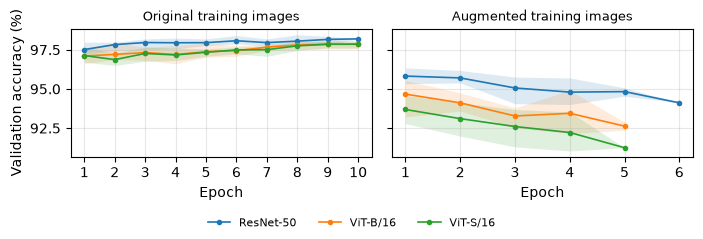

In [9]:
"""
Plots validation accuracy per epoch, one panel for original and one for augmented training images, with the three models
as coloured lines. Each line is the mean over the seeds still training at that epoch, with a min to max band. Both panels
share the y-axis. Saves convergence.png. Gen AI was used to help write this
"""

plt.style.use("default")
RUNS_DIR = Path("runs_10_epochs")
SEEDS = [0, 339, 1, 2, 3, 4, 5, 6, 7, 8]
MODELS = {"ResNet-50": "resnet50",
          "ViT-B/16": "vit_base_patch16_224.augreg_in1k",
          "ViT-S/16": "vit_small_patch16_224.augreg_in1k"}
COLOURS = {"ResNet-50": "tab:blue", "ViT-B/16": "tab:orange", "ViT-S/16": "tab:green"}


def read_validation_accuracy(run_folder):
    # Validation accuracy (in percent) at the end of every epoch the run completed
    event_file = next((run_folder / "Accuracy_val").glob("events.out.tfevents.*"))
    events = EventAccumulator(str(event_file))
    events.Reload()
    return [100 * event.value for event in events.Scalars("Accuracy")]


figure, axes = plt.subplots(1, 2, figsize=(7.0, 2.4), sharey=True, facecolor="white")
for axis, condition in zip(axes, ["original", "augmented"]):
    for model_name, prefix in MODELS.items():
        curves = [read_validation_accuracy(RUNS_DIR / f"{prefix}_{condition}_{seed}") for seed in SEEDS]
        longest_run = max(len(curve) for curve in curves)

        # One row per seed, padded with NaN after the epoch where that seed stopped
        accuracy_by_seed = np.full((len(SEEDS), longest_run), np.nan)
        for row, curve in enumerate(curves):
            accuracy_by_seed[row, :len(curve)] = curve

        # Epoch with the highest validation accuracy for each seed, then the mean and range over seeds
        best_epochs = np.nanargmax(accuracy_by_seed, axis=1) + 1
        print(f"{model_name} {condition} best epoch: mean {best_epochs.mean():.1f}, range {best_epochs.min()} to {best_epochs.max()}")

        epochs = np.arange(1, longest_run + 1)
        mean_curve = np.nanmean(accuracy_by_seed, axis=0)
        low_curve = np.nanmin(accuracy_by_seed, axis=0)
        high_curve = np.nanmax(accuracy_by_seed, axis=0)

        axis.plot(epochs, mean_curve, color=COLOURS[model_name], marker="o", markersize=3, linewidth=1.2, label=model_name)
        axis.fill_between(epochs, low_curve, high_curve, color=COLOURS[model_name], alpha=0.15, linewidth=0)
    axis.set_title(condition.capitalize() + " training images", fontsize=9)
    axis.set_xlabel("Epoch")
    axis.xaxis.set_major_locator(MaxNLocator(integer=True))
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Validation accuracy (%)")

# One shared legend under both panels so it never covers the lines
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, frameon=False)
figure.tight_layout(rect=(0, 0.08, 1, 1))
figure.savefig("convergence.png", dpi=300, facecolor="white")

## 7. Test accuracy on each variant (Table II)
Mean ± SD over ten seeds on Original, Mixed-Same, Mixed-Rand and No-FG for each model and training condition.

In [11]:
# Settings
RESULTS_DIR = "results_10_epochs"
MODEL_FILES = {"ResNet-50": "cnn", "ViT-B/16": "vit", "ViT-S/16": "vit_small"}
VARIANTS = ["original", "mixed_same", "mixed_rand", "no_fg"]

for model_name, file_prefix in MODEL_FILES.items():
    with open(f"{RESULTS_DIR}/{file_prefix}_results.json") as file:
        all_runs = json.load(file)
    print(model_name)
    for variant in VARIANTS:
        # Mean and SD over the seeds, in percentage points
        original_scores = np.array([100 * run["variant_accuracies"][variant] for run in all_runs if run["data_type"] == "original"])
        augmented_scores = np.array([100 * run["variant_accuracies"][variant] for run in all_runs if run["data_type"] == "augmented"])
        print(f"  {variant:<11} original {original_scores.mean():6.2f}±{original_scores.std(ddof=1):4.2f}   "
              f"augmented {augmented_scores.mean():6.2f}±{augmented_scores.std(ddof=1):4.2f}   change {augmented_scores.mean() - original_scores.mean():+6.2f}")

ResNet-50
  original    original  98.53±0.27   augmented  97.48±0.14   change  -1.05
  mixed_same  original  95.15±0.66   augmented  95.08±0.35   change  -0.07
  mixed_rand  original  89.87±1.05   augmented  93.23±0.65   change  +3.36
  no_fg       original  64.91±1.92   augmented  59.80±2.18   change  -5.11
ViT-B/16
  original    original  98.83±0.22   augmented  98.25±0.17   change  -0.58
  mixed_same  original  95.33±0.47   augmented  95.55±0.57   change  +0.21
  mixed_rand  original  88.17±0.86   augmented  94.79±0.43   change  +6.62
  no_fg       original  73.51±1.80   augmented  63.57±2.91   change  -9.94
ViT-S/16
  original    original  98.67±0.24   augmented  97.73±0.18   change  -0.94
  mixed_same  original  94.72±0.57   augmented  93.93±0.60   change  -0.78
  mixed_rand  original  86.87±0.58   augmented  93.59±0.54   change  +6.72
  no_fg       original  72.39±1.72   augmented  60.75±5.05   change -11.64


## 8. Parameters, inference time and training time
Parameter counts, inference time per image (batch 32, 10 warm-up + 20 timed passes) and training time per condition.

In [2]:
# Settings
RESULTS_DIR = "results_10_epochs"
BATCH_SIZE = 32
device = torch.device("cuda")

# The weights are not needed to count parameters or time a forward pass, so the models are not pretrained here
MODELS = {
    "ResNet-50": (CNNModel("resnet50", num_classes=9, pretrained=False), "cnn"),
    "ViT-B/16": (ViTModel("vit_base_patch16_224.augreg_in1k", num_classes=9, pretrained=False), "vit"),
    "ViT-S/16": (ViTModel("vit_small_patch16_224.augreg_in1k", num_classes=9, pretrained=False), "vit_small"),
}

print("Hardware:", torch.cuda.get_device_name(0))

for model_name, (model, file_prefix) in MODELS.items():
    # The trainable parameters are the ones with requires_grad
    total_parameters = sum(p.numel() for p in model.parameters())
    trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Inference time, 10 warm up passes then the average of 20 timed passes, in milliseconds per image
    model = model.to(device).eval()
    images = torch.randn(BATCH_SIZE, 3, 224, 224, device=device)
    with torch.no_grad():
        for _ in range(10):
            model(images)
        torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(20):
            model(images)
        torch.cuda.synchronize()
    inference_ms = (time.perf_counter() - start) / 20 * 1000 / BATCH_SIZE

    # Training time per condition, this includes the validation pass after every epoch but not testing
    with open(f"{RESULTS_DIR}/{file_prefix}_results.json") as file:
        runs = pd.DataFrame(json.load(file))
    runs["minutes"] = runs["training_time_in_secs"] / 60
    summary = runs.groupby("data_type").agg(minutes_mean=("minutes", "mean"), minutes_sd=("minutes", "std"),
                                            epochs_mean=("epochs_run", "mean"), total_minutes=("minutes", "sum"))
    summary["total_minutes"] /= 60

    print(f"\n{model_name}: total {total_parameters / 1e6:.1f}M, trainable {trainable_parameters / 1e6:.1f}M, inference {inference_ms:.2f} ms per image (batch {BATCH_SIZE})")
    print(summary.rename(columns={"total_minutes": "total_hours"}).round(1).to_string())
    torch.cuda.empty_cache()

Hardware: NVIDIA GeForce RTX 3080

ResNet-50: total 23.5M, trainable 23.5M, inference 1.03 ms per image (batch 32)
           minutes_mean  minutes_sd  epochs_mean  total_hours
data_type                                                    
augmented          44.4         7.4          4.5          7.4
original           15.6         4.7          7.0          2.6

ViT-B/16: total 85.8M, trainable 85.8M, inference 3.20 ms per image (batch 32)
           minutes_mean  minutes_sd  epochs_mean  total_hours
data_type                                                    
augmented          43.2         5.6          4.2          7.2
original           35.2        11.2          7.8          5.9

ViT-S/16: total 21.7M, trainable 21.7M, inference 1.13 ms per image (batch 32)
           minutes_mean  minutes_sd  epochs_mean  total_hours
data_type                                                    
augmented          40.8         3.2          4.1          6.8
original           12.6         4.6        

## 9. Per-class accuracy and BG-Gap
Loads all 30 trained models and computes per-class accuracy and BG-Gap on the clean test set. Saves per_class_accuracy.csv and per_class_summary.csv.

In [3]:
# Generative AI was used to help write this codeblock
# Settings, the same paths as the notebooks
IMAGE_SIZE = 224
BATCH_SIZE = 64
SEEDS = [0, 339, 1, 2, 3, 4, 5, 6, 7, 8]
RESULTS = pathlib.Path("results_10_epochs")
TEST_INSTANCES = pathlib.Path("data") / "bg_challenge_clean"
# Only these variants are needed for the per class accuracy and BG-Gap
VARIANTS = ["original", "mixed_same", "mixed_rand"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Class name to label number, from the validation folders (same class folders as training) so the labels match the models
train_class_to_idx = ImageFolderEval(pathlib.Path("data") / "rebuild" / "in9_val").class_to_idx
class_names = sorted(train_class_to_idx, key=train_class_to_idx.get)

# Model name, how to build it, the start of its weight file names and its normalisation
MODELS = {
    "ResNet-50": (lambda: CNNModel("resnet50", num_classes=9, pretrained=False), "resnet50", IMAGENET_MEAN, IMAGENET_STD),
    "ViT-B/16": (lambda: ViTModel("vit_base_patch16_224.augreg_in1k", num_classes=9, pretrained=False), "vit_base_patch16_224.augreg_in1k", VIT_MEAN, VIT_STD),
    "ViT-S/16": (lambda: ViTModel("vit_small_patch16_224.augreg_in1k", num_classes=9, pretrained=False), "vit_small_patch16_224.augreg_in1k", VIT_MEAN, VIT_STD),
}

# Load every test image once as 0 to 255 integers, so it is not reloaded for each of the 30 models
# The resizing is the same as ImageFolderEval, the normalisation is done on the GPU for each model
to_bytes = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.PILToTensor()])
test_images, test_labels = {}, {}
for variant in VARIANTS:
    dataset = fix_test_labels(ImageFolderEval(TEST_INSTANCES / variant / "val", image_size=IMAGE_SIZE), train_class_to_idx)
    test_images[variant] = torch.stack([to_bytes(Image.open(path).convert("RGB")) for path, _ in dataset.samples])
    test_labels[variant] = torch.tensor([label for _, label in dataset.samples])
    print(f"{variant}: {len(dataset)} images loaded")


def predict(model, images, mean, std):
    # Predicted class of every image, in float32 and eval mode as in the experiments
    mean = torch.tensor(mean, device=device).view(1, 3, 1, 1)
    std = torch.tensor(std, device=device).view(1, 3, 1, 1)
    predictions = []
    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            batch = images[start:start + BATCH_SIZE].to(device).float() / 255
            predictions.append(model((batch - mean) / std).argmax(dim=1).cpu())
    return torch.cat(predictions)


# Per class accuracy on each variant, for every run
rows = []
for model_name, (make_model, file_prefix, mean, std) in MODELS.items():
    model = make_model().to(device)
    for data_type in ["original", "augmented"]:
        for seed in SEEDS:
            model.load_state_dict(torch.load(RESULTS / f"{file_prefix}_{data_type}_{seed}_weights.pt", map_location=device))
            model.eval()
            for variant in VARIANTS:
                predictions = predict(model, test_images[variant], mean, std)
                labels = test_labels[variant]
                for class_index, class_name in enumerate(class_names):
                    in_class = labels == class_index
                    rows.append({"model": model_name, "condition": data_type, "seed": seed, "variant": variant, "class": class_name,
                                 "accuracy": 100 * (predictions[in_class] == class_index).float().mean().item()})
            print(model_name, data_type, seed, "done")

per_class = pd.DataFrame(rows)
per_class.to_csv(RESULTS / "per_class_accuracy.csv", index=False)

# Per class BG-Gap for each run is mixed_same minus mixed_rand accuracy on that class
wide = per_class.pivot_table(index=["model", "condition", "seed", "class"], columns="variant", values="accuracy").reset_index()
wide["bg_gap"] = wide["mixed_same"] - wide["mixed_rand"]

# Mean and standard deviation over the seeds
summary = wide.groupby(["model", "condition", "class"]).agg(
    original_mean=("original", "mean"), original_std=("original", "std"),
    mixed_rand_mean=("mixed_rand", "mean"), mixed_rand_std=("mixed_rand", "std"),
    bg_gap_mean=("bg_gap", "mean"), bg_gap_std=("bg_gap", "std")).round(2)
summary.to_csv(RESULTS / "per_class_summary.csv")

# BG-Gap per class, original against augmented, for each model
for model_name in MODELS:
    table = summary.loc[model_name]["bg_gap_mean"].unstack("condition")
    table["change"] = table["augmented"] - table["original"]
    print(f"\n{model_name} BG-Gap per class (mean over seeds, percentage points)")
    print(table.round(2).to_string())

# Which classes are hardest on mixed_rand, original models
print("\nMixed-Rand accuracy per class, original models")
print(summary.xs("original", level="condition")["mixed_rand_mean"].unstack("model").round(2).to_string())

original: 3889 images loaded
mixed_same: 3889 images loaded
mixed_rand: 3889 images loaded
ResNet-50 original 0 done
ResNet-50 original 339 done
ResNet-50 original 1 done
ResNet-50 original 2 done
ResNet-50 original 3 done
ResNet-50 original 4 done
ResNet-50 original 5 done
ResNet-50 original 6 done
ResNet-50 original 7 done
ResNet-50 original 8 done
ResNet-50 augmented 0 done
ResNet-50 augmented 339 done
ResNet-50 augmented 1 done
ResNet-50 augmented 2 done
ResNet-50 augmented 3 done
ResNet-50 augmented 4 done
ResNet-50 augmented 5 done
ResNet-50 augmented 6 done
ResNet-50 augmented 7 done
ResNet-50 augmented 8 done
ViT-B/16 original 0 done
ViT-B/16 original 339 done
ViT-B/16 original 1 done
ViT-B/16 original 2 done
ViT-B/16 original 3 done
ViT-B/16 original 4 done
ViT-B/16 original 5 done
ViT-B/16 original 6 done
ViT-B/16 original 7 done
ViT-B/16 original 8 done
ViT-B/16 augmented 0 done
ViT-B/16 augmented 339 done
ViT-B/16 augmented 1 done
ViT-B/16 augmented 2 done
ViT-B/16 augmente

## 10. Training and validation loss after the best epoch
For each original run, the losses at the best validation accuracy epoch and at the last epoch.

In [11]:
RUNS_DIR = Path("runs_10_epochs")
SEEDS = [0, 339, 1, 2, 3, 4, 5, 6, 7, 8]
MODELS = {"ResNet-50": "resnet50",
          "ViT-B/16": "vit_base_patch16_224.augreg_in1k",
          "ViT-S/16": "vit_small_patch16_224.augreg_in1k"}


def read_scalar(run_folder, subfolder, tag):
    # One value per epoch
    events = EventAccumulator(str(next((run_folder / subfolder).glob("events.out.tfevents.*"))))
    events.Reload()
    return np.array([event.value for event in events.Scalars(tag)])

# Losses at the best validation-accuracy epoch and at the last epoch of each original run
for model_name, prefix in MODELS.items():
    for seed in SEEDS:
        run_folder = RUNS_DIR / f"{prefix}_original_{seed}"
        val_accuracy = read_scalar(run_folder, "Accuracy_val", "Accuracy")
        train_loss = read_scalar(run_folder, "Loss_train", "Loss")
        val_loss = read_scalar(run_folder, "Loss_val", "Loss")
        best = int(np.argmax(val_accuracy))
        print(f"{model_name} seed {seed}: best epoch {best + 1} of {len(val_accuracy)}, "
              f"train loss {train_loss[best]:.3f} to {train_loss[-1]:.3f}, val loss {val_loss[best]:.3f} to {val_loss[-1]:.3f}")

ResNet-50 seed 0: best epoch 5 of 8, train loss 0.005 to 0.001, val loss 0.099 to 0.112
ResNet-50 seed 339: best epoch 4 of 7, train loss 0.009 to 0.002, val loss 0.088 to 0.095
ResNet-50 seed 1: best epoch 6 of 9, train loss 0.002 to 0.001, val loss 0.104 to 0.114
ResNet-50 seed 2: best epoch 2 of 5, train loss 0.056 to 0.006, val loss 0.089 to 0.097
ResNet-50 seed 3: best epoch 4 of 7, train loss 0.010 to 0.002, val loss 0.106 to 0.129
ResNet-50 seed 4: best epoch 8 of 10, train loss 0.001 to 0.001, val loss 0.110 to 0.113
ResNet-50 seed 5: best epoch 1 of 4, train loss 0.782 to 0.009, val loss 0.086 to 0.123
ResNet-50 seed 6: best epoch 3 of 6, train loss 0.020 to 0.002, val loss 0.087 to 0.141
ResNet-50 seed 7: best epoch 2 of 5, train loss 0.059 to 0.006, val loss 0.069 to 0.119
ResNet-50 seed 8: best epoch 6 of 9, train loss 0.003 to 0.001, val loss 0.083 to 0.104
ViT-B/16 seed 0: best epoch 7 of 10, train loss 0.001 to 0.000, val loss 0.178 to 0.205
ViT-B/16 seed 339: best epoch